# New wd=0.1 benchmark follow-up (execution preparation)
Exploratory validation analysis; historical saved outputs cleared.
Historical numerical prose is background, not a result of this benchmark.
Output-key scrubbing does not establish a serial algorithm. MB16 legacy scrub results
are invalidated by F25; use Section R corrected results. No new test access is permitted.


# MB21 — Is Player Knowledge Stored but Not Used?

**Track B · Follow-up to MB04, MB15, MB16 · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | MB04, MB15 and MB18 show that changing the player moves Δ no more than a fake player vector of the same size or shape (C2 negative on 7 models), and removing the player at inference costs no NLL. Two explanations fit: (a) the player embeddings **contain no** player-specific habits beyond role; (b) they **do contain** habits, but the network **does not read** that part on conflicts. This notebook separates the two. |
| **Why it matters** | It is the difference between "the model contains player information" and "the model uses player identity to change its prediction" (research question list, claims 1–3 of Part 2F). |
| **Tests** | (1) **Stored?** Do player embeddings predict each player's training action habits, beyond what their role predicts? Representational similarity (RSA) and cross-validated decoding, on every seed. (2) **Used?** Split each player vector into the part that predicts habits (habit subspace) and the rest; swap only one part with the partner's; which part moves Δ, and does the change follow the habits (C3)? |
| **Population** | Player embeddings of the 350 dedicated players (training split for habits). Conflict tests on P-player validation, estimation half primary. |
| **Status** | Follow-up after MB14–MB18; exploratory; not part of the MB12 lock. The plan is written and fingerprinted before any number. No test data. |
| **Outputs** | `config/MB21_plan.json`, `results/MB21_*`, `figures/MB21_*` |

In [1]:
import os
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: False | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)
import mi_src.conflict as conflict
from scipy.stats import spearmanr
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified_at_start = fingerprint.verify_files(MANIFEST)
manifest_before = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
assert IDENTITY == "player", "BLOCKED: MB14-MB16 follow up MB04-MB12, which studied the player variable."
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_DRAWS = SETTINGS["n_draws"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
# No test view is built or read anywhere in MB14-MB16 (mi_setup.unlock_test_view is never called).
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
ALL = circuits.all_components(N_LAYERS, N_HEADS)
FEATURES = list(bundle["encoded"].tensors.keys())
IDENTITY_FEATURES = [name for name in ["player", "team", "role", "competition"] if name in FEATURES]
CONTEXT_FEATURES = [name for name in FEATURES if name not in IDENTITY_FEATURES]

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
print(f"verified files: {len(verified_at_start)} | primary seed {PRIMARY_SEED} | seeds {SEEDS}")
print(f"P-player rows: {len(p_player):,} (discovery {len(discovery):,}, estimation {len(estimation):,}) | "
      f"index-0: {len(index0):,} | matched controls: {len(controls):,}")
print(f"components: {ALL}")
print(f"identity inputs: {IDENTITY_FEATURES} | context inputs ({len(CONTEXT_FEATURES)}): {CONTEXT_FEATURES}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 99 | primary seed 103 | seeds [100, 101, 102, 103, 104]
P-player rows: 1,744 (discovery 1,215, estimation 529) | index-0: 8,947 | matched controls: 252
components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
identity inputs: ['player', 'team', 'role', 'competition'] | context inputs (15): ['zone', 'period', 'minute_bin', 'score_diff', 'play_pattern', 'poss_len', 'possession_flag', 'prev_action', 'prev_outcome', 'prev_end_zone', 'same_player_as_prev', 'x_norm', 'y_norm', 'dt', 't_poss']


In [4]:
# Per-player facts from the TRAINING split, in the model's own (T300) player indices:
# modal role, modal team, number of training events. Used for frequency bands, role centroids and
# team-matched partners. Nothing here reads validation labels.
ENCODED = bundle["encoded"].tensors
assert len(ENCODED["player"]) == len(events), "BLOCKED: encoded tensors are not one row per event."
assert "split" in events.columns, "BLOCKED: events has no split column, so training counts cannot be computed."
TRAIN_ROWS = np.where(events["split"].to_numpy() == "train")[0]
_train = pd.DataFrame({name: ENCODED[name][torch.as_tensor(TRAIN_ROWS, device=ENCODED[name].device)].cpu().numpy()
                       for name in ["player", "role", "team"]})
_train = _train[_train["player"] > 0]
PLAYER_META = _train.groupby("player").agg(role=("role", lambda s: s.value_counts().index[0]),
                                           team=("team", lambda s: s.value_counts().index[0]),
                                           train_events=("role", "size"))
FREQUENCY_CUT = 1000


def frequency_band(players):
    counts = PLAYER_META["train_events"].reindex(np.asarray(players)).to_numpy()
    return np.where(np.isnan(counts), "no training events",
                    np.where(counts >= FREQUENCY_CUT, f">= {FREQUENCY_CUT} training events", f"< {FREQUENCY_CUT} training events"))


PLAYER_TABLE = MODEL.embedding.embeddings["player"].weight.detach()
ROLE_CENTROID = {int(role): PLAYER_TABLE[torch.as_tensor(group.index.to_numpy(), device=PLAYER_TABLE.device)].mean(0)
                 for role, group in PLAYER_META.groupby("role")}
print(f"players with training events: {len(PLAYER_META)} | roles: {len(ROLE_CENTROID)} | "
      f"frequency bands: {pd.Series(frequency_band(PLAYER_META.index)).value_counts().to_dict()}")


def player_vector_edit(new_vectors, players, positions):
    """Edit for site factor_player: at the scored position, swap the player's own embedding for new_vectors.

    The factor site is the sum of the group's embeddings; subtracting the player's own row and adding the new
    vector changes only the player part, whatever else the group contains."""
    own = PLAYER_TABLE[torch.as_tensor(np.asarray(players), device=PLAYER_TABLE.device)]

    def edit(value):
        new = value.clone()
        rows = torch.arange(len(positions), device=value.device)
        new[rows, positions] = value[rows, positions] - own.to(value.device) + new_vectors.to(value.device)
        return new
    return edit


def control_vectors(players, kind, rng):
    """Replacement player vectors for the identity controls (rows whose control is undefined get NaN)."""
    players = np.asarray(players)
    out = torch.full((len(players), PLAYER_TABLE.shape[1]), float("nan"), device=PLAYER_TABLE.device)
    for i, player in enumerate(players):
        if player not in PLAYER_META.index:
            continue
        role = int(PLAYER_META.loc[player, "role"])
        centroid = ROLE_CENTROID[role]
        own = PLAYER_TABLE[player]
        if kind == "role centroid":
            out[i] = centroid
        elif kind == "distribution-matched deviation":
            others = PLAYER_META.index[(PLAYER_META["role"] == role) & (PLAYER_META.index != player)
                                       & (PLAYER_META.index != partner_of.get(player, -1))].to_numpy()
            if len(others) == 0:
                continue
            other = PLAYER_TABLE[int(rng.choice(others))] - centroid
            out[i] = centroid + other * (own - centroid).norm() / (other.norm() + 1e-12)
        elif kind == "shuffled coordinates":
            out[i] = own[torch.as_tensor(rng.permutation(len(own)), device=own.device)]
        else:
            raise ValueError(kind)
    return out


def team_matched_partner(player):
    """Same modal role AND team, nearest log training count; -1 if none."""
    if player not in PLAYER_META.index:
        return -1
    row = PLAYER_META.loc[player]
    pool = PLAYER_META[(PLAYER_META["role"] == row["role"]) & (PLAYER_META["team"] == row["team"])
                       & (PLAYER_META.index != player)]
    if len(pool) == 0:
        return -1
    gap = np.abs(np.log(pool["train_events"].to_numpy()) - np.log(row["train_events"]))
    return int(pool.index[np.lexsort((pool.index.to_numpy(), gap))[0]])

players with training events: 350 | roles: 23 | frequency bands: {'< 1000 training events': 333, '>= 1000 training events': 17}


## 1. Terms

| Term | Meaning here |
|---|---|
| **Habit profile** | For a player: the log-lift of each of the 15 actions in training, log(share of the action in the player's training events / its base rate), smoothed towards the base rate with 20 pseudo-events. |
| **Role-adjusted habit** | Habit profile minus the average profile of the player's role: what is specific to the player. |
| **RSA** | Spearman correlation, over all pairs of players, between embedding distance (cosine) and habit distance (Euclidean). Significance by permuting players (Mantel test, 2,000 permutations). |
| **Decoding R²** | Ridge regression from the 128-d player embedding to the 15-d habit profile, cross-validated over 5 folds of players; R² on held-out players. "Beyond role": the embedding with role centroids removed predicting the role-adjusted habit. Baseline: the same with habit rows shuffled across players. |
| **Habit subspace** | The row space of the decoder's weight matrix (at most 15 dimensions) in the 128-d embedding space, fitted on all players. |
| **Swap of one part** | The player vector at the scored event becomes own vector − own part + partner's part, for the habit part or for the rest. |

## 2. The plan (written before any number)

In [5]:
PLAN = {
    "status": "follow-up after MB14-MB18; exploratory; not part of the MB12 lock",
    "habits": "log-lift of 15 actions per dedicated player from the training split, smoothed with 20 pseudo-events of the base rate; role-adjusted = minus the role mean",
    "stored_tests": ["RSA embedding cosine distance vs habit distance (all players; role-adjusted within role); Mantel p from 2,000 permutations",
                     "ridge decoding embedding -> habit, 5-fold over players, R2 vs 200 shuffled-habit baselines; role-adjusted version",
                     "every seed 100-104"],
    "stored_reading": "habits are STORED beyond role if the role-adjusted decoding R2 exceeds the 95th percentile of its shuffled baseline on at least 4 of 5 seeds",
    "used_tests": ("on P-player conflicts: swap only the habit-subspace part, or only the remaining part, of the player vector with the partner's; "
                   "|change in Delta|, its share of the full swap, and C3 (correlation of the model's change with the habit reference change) for each"),
    "used_reading": ("habits are USED if the habit-part swap has C3 CI above 0 and C3 above the rest-part swap's (paired CI above 0); "
                     "STORED BUT NOT USED if habits are stored and the habit-part swap's C3 CI includes 0"),
    "half": "estimation primary, discovery alongside"
}
plan_path = OUT / "config" / "MB21_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB21_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB21_plan.json
{
 "status": "follow-up after MB14-MB18; exploratory; not part of the MB12 lock",
 "habits": "log-lift of 15 actions per dedicated player from the training split, smoothed with 20 pseudo-events of the base rate; role-adjusted = minus the role mean",
 "stored_tests": [
  "RSA embedding cosine distance vs habit distance (all players; role-adjusted within role); Mantel p from 2,000 permutations",
  "ridge decoding embedding -> habit, 5-fold over players, R2 vs 200 shuffled-habit baselines; role-adjusted version",
  "every seed 100-104"
 ],
 "stored_reading": "habits are STORED beyond role if the role-adjusted decoding R2 exceeds the 95th percentile of its shuffled baseline on at least 4 of 5 seeds",
 "used_tests": "on P-player conflicts: swap only the habit-subspace part, or only the remaining part, of the player vector with the partner's; |change in Delta|, its share of the full swap, and C3 (correlation of the model's change with the habit reference change) 

## 3. Habit profiles from the training split

In [6]:
train_actions = events["action_id"].to_numpy()[TRAIN_ROWS]
train_players = ENCODED["player"][torch.as_tensor(TRAIN_ROWS, device=ENCODED["player"].device)].cpu().numpy()
N_ACTIONS = conflict.NUM_ACTIONS
base = np.bincount(train_actions, minlength=N_ACTIONS) / len(train_actions)
PLAYERS = PLAYER_META.index.to_numpy()
counts = np.zeros((len(PLAYERS), N_ACTIONS))
index_of = {p: i for i, p in enumerate(PLAYERS)}
mask = np.isin(train_players, PLAYERS)
np.add.at(counts, (np.array([index_of[p] for p in train_players[mask]]), train_actions[mask]), 1)
smoothed = (counts + 20 * base) / (counts.sum(1, keepdims=True) + 20)
HABIT = np.log(smoothed / base)
ROLE = PLAYER_META.loc[PLAYERS, "role"].to_numpy()
role_mean = pd.DataFrame(HABIT).groupby(ROLE).transform("mean").to_numpy()
HABIT_ADJ = HABIT - role_mean
try:
    from src.data import ACTION_NAMES
except ImportError:
    ACTION_NAMES = [str(i) for i in range(N_ACTIONS)]
spread = pd.DataFrame({"action": ACTION_NAMES[:N_ACTIONS], "SD of log-lift across players": HABIT.std(0),
                       "SD within role": HABIT_ADJ.std(0)}).sort_values("SD within role", ascending=False)
print(f"players: {len(PLAYERS)} | roles: {len(np.unique(ROLE))}")
print(spread.round(3).to_string(index=False))

players: 350 | roles: 23
        action  SD of log-lift across players  SD within role
         OTHER                          1.874           1.738
         CROSS                          1.455           0.934
          SHOT                          1.202           0.820
      FOUL_WON                          0.945           0.724
       DRIBBLE                          1.129           0.704
FOUL_COMMITTED                          0.962           0.700
     CLEARANCE                          1.146           0.649
          LOSS                          1.007           0.573
          DUEL                          0.781           0.444
  INTERCEPTION                          0.757           0.436
     GK_ACTION                          1.353           0.395
      RECOVERY                          0.326           0.296
     PASS_LONG                          0.400           0.220
    PASS_SHORT                          0.287           0.195
         CARRY                          0.195

## 4. Stored? RSA and decoding, on every seed

In [7]:
def embedding_table(model):
    return model.embedding.embeddings["player"].weight.detach().cpu().numpy()[PLAYERS]


def cosine_distance(matrix):
    unit = matrix / (np.linalg.norm(matrix, axis=1, keepdims=True) + 1e-12)
    return 1 - unit @ unit.T


def euclidean(matrix):
    return np.linalg.norm(matrix[:, None, :] - matrix[None, :, :], axis=-1)


def rsa(emb_dist, habit_dist, pairs_mask, n_perm=2000, seed=0):
    iu = np.where(pairs_mask)
    observed = spearmanr(emb_dist[iu], habit_dist[iu]).correlation
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        order = rng.permutation(len(habit_dist))
        null.append(spearmanr(emb_dist[iu], habit_dist[order][:, order][iu]).correlation)
    return float(observed), float((np.sum(np.array(null) >= observed) + 1) / (n_perm + 1)), float(np.percentile(null, 95))


def decode(features, targets, groups_seed=0, n_shuffle=200):
    folds = np.random.default_rng(groups_seed).integers(0, 5, len(features))
    def cv_r2(y):
        predicted = np.zeros_like(y)
        for k in range(5):
            train, test = folds != k, folds == k
            model = RidgeCV(alphas=np.logspace(-2, 4, 13)).fit(features[train], y[train])
            predicted[test] = model.predict(features[test])
        return 1 - ((y - predicted) ** 2).sum() / ((y - y.mean(0)) ** 2).sum()
    observed = cv_r2(targets)
    rng = np.random.default_rng(groups_seed + 1)
    null = [cv_r2(targets[rng.permutation(len(targets))]) for _ in range(n_shuffle)]
    return float(observed), float(np.percentile(null, 95)), float(np.mean(null))


upper = np.triu(np.ones((len(PLAYERS), len(PLAYERS)), dtype=bool), 1)
same_role = upper & (ROLE[:, None] == ROLE[None, :])
stored_rows = []
for seed in SEEDS:
    model = MODEL if seed == PRIMARY_SEED else mi_setup.load_model(run_dir(seed), bundle)
    emb = embedding_table(model)
    emb_adj = emb - pd.DataFrame(emb).groupby(ROLE).transform("mean").to_numpy()
    r_all, p_all, null_all = rsa(cosine_distance(emb), euclidean(HABIT), upper, seed=seed)
    r_role, p_role, null_role = rsa(cosine_distance(emb), euclidean(HABIT_ADJ), same_role, seed=seed)
    r2, r2_null95, r2_null_mean = decode(emb, HABIT, seed)
    r2_adj, r2_adj_null95, r2_adj_null_mean = decode(emb_adj, HABIT_ADJ, seed)
    stored_rows.append({"seed": seed, "RSA all pairs": r_all, "RSA p": p_all, "RSA within role (role-adjusted habits)": r_role, "RSA within role p": p_role,
                        "decoding R2": r2, "R2 shuffled 95th pct": r2_null95,
                        "decoding R2 beyond role": r2_adj, "beyond-role shuffled 95th pct": r2_adj_null95,
                        "stored beyond role": r2_adj > r2_adj_null95})
    if seed != PRIMARY_SEED:
        del model
stored = pd.DataFrame(stored_rows)
stored.to_csv(OUT / "results" / "MB21_stored.csv", index=False)
print(stored.round(4).to_string(index=False))
STORED = int(stored["stored beyond role"].sum()) >= 4
print(f"\nhabits STORED beyond role (plan rule, >= 4 of 5 seeds): {STORED}")

 seed  RSA all pairs  RSA p  RSA within role (role-adjusted habits)  RSA within role p  decoding R2  R2 shuffled 95th pct  decoding R2 beyond role  beyond-role shuffled 95th pct  stored beyond role
  100         0.0303 0.0005                                  0.0151             0.2189       0.0551               -0.0040                   0.1078                        -0.0036                True
  101         0.0280 0.0005                                  0.0146             0.2204       0.0421               -0.0035                   0.0610                        -0.0043                True
  102         0.0330 0.0005                                  0.0105             0.2704       0.0303               -0.0032                   0.1044                        -0.0035                True
  103         0.0268 0.0005                                  0.0166             0.1909       0.0250               -0.0037                   0.0764                        -0.0035                True
  104     

## 5. Used? Swap only the habit part, or only the rest, of the player vector

The habit subspace is the row space of the ridge decoder from embedding to habit profile (fitted on all players, seed 103). On every P-player conflict, the player vector at the scored event is changed in one of three ways, each towards the matched partner: the whole vector (as MB04), only its habit-subspace part, or only the rest. For each: how much Δ moves, and whether the model's whole output distribution moves the way the partner's habits differ from the player's (C3, using the player-only identity reference exactly as MB04 and MB15).

In [8]:
emb = embedding_table(MODEL)
decoder = RidgeCV(alphas=np.logspace(-2, 4, 13)).fit(emb, HABIT)
basis = np.linalg.svd(decoder.coef_, full_matrices=False)[2]          # [<=15, 128], orthonormal rows
BASIS = torch.as_tensor(basis, dtype=torch.float32, device=DEVICE)
print(f"habit subspace: {basis.shape[0]} dimensions of {emb.shape[1]}")
share_norm = np.linalg.norm(emb @ basis.T, axis=1) / np.linalg.norm(emb, axis=1)
print(f"share of each player vector's norm inside the habit subspace: median {np.median(share_norm):.3f}")

idplayer_state = torch.load(OUT / "artifacts" / "conflict" / "references" / "id_player_seed0.pt", map_location="cpu", weights_only=False)
idplayer = conflict.IdPlayer(idplayer_state["vocabulary_sizes"]); idplayer.load_state_dict(idplayer_state["state"])
with torch.no_grad():
    all_players = torch.arange(idplayer_state["vocabulary_sizes"]["player"])
    HABIT_REF = torch.log_softmax(idplayer(all_players.unsqueeze(1), torch.zeros(len(all_players), 0)) / idplayer_state["temperature"], dim=-1).numpy()


def centred_log_probs(logits):
    values = mi_metrics.log_softmax(logits.cpu().numpy())
    return values - values.mean(1, keepdims=True)


@torch.no_grad()
def part_swaps(table):
    frames = []
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        chunk = table.iloc[part]
        own = chunk["player"].to_numpy()
        partner = np.array([partner_of.get(p, -1) for p in own])
        valid = partner > 0
        partner = np.where(valid, partner, own)
        own_vec = PLAYER_TABLE[torch.as_tensor(own, device=PLAYER_TABLE.device)]
        partner_vec = PLAYER_TABLE[torch.as_tensor(partner, device=PLAYER_TABLE.device)]
        own_habit = (own_vec @ BASIS.T) @ BASIS
        partner_habit = (partner_vec @ BASIS.T) @ BASIS
        new_vectors = {"whole vector": partner_vec,
                       "habit part only": own_vec - own_habit + partner_habit,
                       "rest only": partner_vec - partner_habit + own_habit}
        base_logits = mi_metrics.at_target(hooks.forward(MODEL, inputs)[0], positions)
        base_delta = mi_metrics.delta(base_logits, a_ctx, a_id)
        reference_change = HABIT_REF[partner] - HABIT_REF[own]
        reference_change -= reference_change.mean(1, keepdims=True)
        frame = {"match_id": chunk["match_id"].to_numpy(), "half": chunk["half"].to_numpy(), "valid": valid}
        for name, vectors in new_vectors.items():
            logits = mi_metrics.at_target(hooks.forward(MODEL, inputs, replace={"factor_player": player_vector_edit(vectors, own, positions)})[0], positions)
            change = centred_log_probs(logits) - centred_log_probs(base_logits)
            frame[f"{name}: change in Delta"] = mi_metrics.delta(logits, a_ctx, a_id) - base_delta
            frame[f"{name}: C3 r"] = (change * reference_change).sum(1) / (np.sqrt((change ** 2).sum(1) * (reference_change ** 2).sum(1)) + 1e-12)
        frames.append(pd.DataFrame(frame))
    return pd.concat(frames, ignore_index=True)


swaps = part_swaps(p_player)
swaps = swaps[swaps["valid"]].reset_index(drop=True)
swaps.to_parquet(OUT / "results" / "MB21_part_swaps_events.parquet", index=False)
used_rows = []
for half in ["estimation", "discovery"]:
    part = swaps[swaps.half == half]
    m = part["match_id"]
    whole = np.abs(part["whole vector: change in Delta"]).mean()
    for name in ["whole vector", "habit part only", "rest only"]:
        size = mi_metrics.summarise(np.abs(part[f"{name}: change in Delta"]), m, N_BOOT)
        c3 = mi_metrics.summarise(part[f"{name}: C3 r"], m, N_BOOT)
        used_rows.append({"half": half, "swap": name, "n": size["n"], "mean |change in Delta|": size["mean"],
                          "share of the whole swap": size["mean"] / whole, "C3 r": c3["mean"], "C3 CI low": c3["ci_low"], "C3 CI high": c3["ci_high"]})
    diff = mi_metrics.summarise(part["habit part only: C3 r"] - part["rest only: C3 r"], m, N_BOOT)
    used_rows.append({"half": half, "swap": "C3 habit part minus rest (paired)", "n": diff["n"], "C3 r": diff["mean"],
                      "C3 CI low": diff["ci_low"], "C3 CI high": diff["ci_high"]})
used = pd.DataFrame(used_rows)
used.to_csv(OUT / "results" / "MB21_used.csv", index=False)
print(used.round(4).to_string(index=False))
est = used[used.half == "estimation"].set_index("swap")
habit_used = est.loc["habit part only", "C3 CI low"] > 0 and est.loc["C3 habit part minus rest (paired)", "C3 CI low"] > 0
habit_null = est.loc["habit part only", "C3 CI low"] <= 0 <= est.loc["habit part only", "C3 CI high"]
verdict = "USED" if habit_used else ("STORED BUT NOT USED" if (STORED and habit_null) else
                                    ("NOT STORED (beyond role)" if not STORED else "UNDECIDED"))
print(f"\nverdict (plan rule): {verdict}")

habit subspace: 15 dimensions of 128
share of each player vector's norm inside the habit subspace: median 0.493


      half                              swap    n  mean |change in Delta|  share of the whole swap    C3 r  C3 CI low  C3 CI high
estimation                      whole vector  529                  0.7700                   1.0000  0.0332    -0.0287      0.0954
estimation                   habit part only  529                  0.3424                   0.4446  0.1088     0.0474      0.1648
estimation                         rest only  529                  0.6690                   0.8688 -0.0405    -0.0936      0.0102
estimation C3 habit part minus rest (paired)  529                     NaN                      NaN  0.1492     0.0840      0.2087
 discovery                      whole vector 1188                  0.6246                   1.0000  0.0921     0.0355      0.1448
 discovery                   habit part only 1188                  0.4194                   0.6715  0.1103     0.0339      0.1846
 discovery                         rest only 1188                  0.5641                 

## 6. The picture

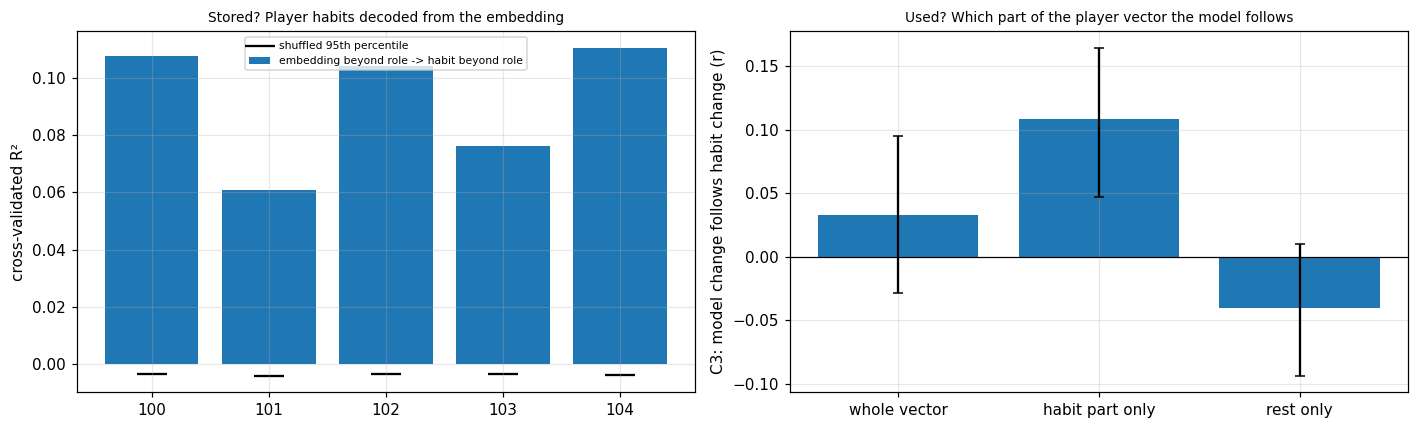

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(stored["seed"].astype(str), stored["decoding R2 beyond role"], label="embedding beyond role -> habit beyond role")
axes[0].scatter(stored["seed"].astype(str), stored["beyond-role shuffled 95th pct"], color="black", marker="_", s=400, label="shuffled 95th percentile")
axes[0].set_ylabel("cross-validated R²"); axes[0].set_title("Stored? Player habits decoded from the embedding", fontsize=9); axes[0].legend(fontsize=7)
block = used[(used.half == "estimation") & used.swap.isin(["whole vector", "habit part only", "rest only"])]
axes[1].bar(block["swap"], block["C3 r"], yerr=[block["C3 r"] - block["C3 CI low"], block["C3 CI high"] - block["C3 r"]], capsize=3)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("C3: model change follows habit change (r)"); axes[1].set_title("Used? Which part of the player vector the model follows", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB21_stored_vs_used.png", bbox_inches="tight", dpi=150); plt.show()

## 7. Summary and integrity

In [10]:
summary = {"status": PLAN["status"], "stored": stored.to_dict(orient="records"), "used": used.to_dict(orient="records"),
           "habit_subspace_dims": int(basis.shape[0]), "verdict": verdict, "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB21_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB21_summary.json": OUT / "results" / "MB21_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB21", "experiment": "player knowledge: stored vs used", "seed": PRIMARY_SEED, "run_mode": RUN_MODE})

In [11]:
verified_at_end = fingerprint.verify_files(MANIFEST)
manifest_after = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
changed = sorted(name for name in manifest_before if manifest_after.get(name) != manifest_before[name])
print(f"manifest entries verified at the end: {len(verified_at_end)}")
print("earlier entries whose fingerprint changed during this notebook:", changed if changed else "none")
assert not changed, "BLOCKED: an earlier Track B file changed while this notebook ran."
test_log = OUT / "logs" / "test_access_log.jsonl"
test_lines = len(test_log.read_text().strip().splitlines()) if test_log.exists() and test_log.read_text().strip() else 0
print(f"test accesses recorded so far: {test_lines} (MB12 recorded exactly one; this notebook adds none)")

manifest entries verified at the end: 101
earlier entries whose fingerprint changed during this notebook: none
test accesses recorded so far: 1 (MB12 recorded exactly one; this notebook adds none)


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:
- Evidence label: